In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm, expon

Given data $(x = (x_1, x_2, \dots, x_n))$, where each $(x_i\in{0,1})$, the Bernoulli likelihood is

$$
L(p \mid x) \;=\; \prod_{i=1}^n p^{x_i}\,(1 - p)^{1 - x_i}.
$$

Taking logs gives the log-likelihood:

$$
\ell(p \mid x)
= \log L(p \mid x)
= \sum_{i=1}^n \bigl[x_i\,\ln(p)\;+\;(1 - x_i)\,\ln(1 - p)\bigr].
$$


[0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0]
MLE estimate of p: 0.230


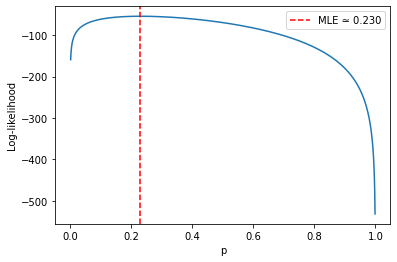

In [5]:

# 1) Simulate some Bernoulli trials with true p = 0.3
np.random.seed(0)
data = np.random.binomial(1, 0.3, size=100)   # coin flips with random.binomial(n, p, size=None)

print(data) 

# 2) Define the log-likelihood for a given p
def log_likelihood(p, x):
    return np.sum(x * np.log(p) + (1 - x) * np.log(1 - p))

# 3) Evaluate it on a fine grid between 0.01 and 0.99
ps = np.linspace(0.001, 0.999, 1000)         
lls = [log_likelihood(p, data) for p in ps]

# 4) Find the p that maximizes it
p_mle = ps[np.argmax(lls)]
print(f"MLE estimate of p: {p_mle:.3f}")

# (Optional) plot the log-likelihood curve
plt.plot(ps, lls)
plt.axvline(p_mle, color='red', linestyle='--', label=f'MLE ≃ {p_mle:.3f}')
plt.xlabel('p')
plt.ylabel('Log-likelihood')
plt.legend()
plt.show()


# Extended Unbinned MLE (Gaussian + Exponential)

Simulate signal events from $(\mathcal N(\mu,\sigma))$ and background from $(\mathrm{exp}(\lambda))$, data $({x_i})$.

**Signal PDF**  
$$
f_{\rm sig}(x;\mu,\sigma)
=\frac{1}{\sqrt{2\pi}\,\sigma}
\exp\!\Bigl(-\tfrac{(x-\mu)^2}{2\sigma^2}\Bigr)
$$

**Background PDF**  
$$
f_{\rm bkg}(x;\lambda)
=\lambda\,e^{-\lambda\,x}
$$

**Mixture PDF**  
$$
f(x)
=\frac{N_s\,f_{\rm sig}(x)+N_b\,f_{\rm bkg}(x)}{N_s+N_b}
$$

**Log-likelihood**  
$$
\ell(\theta)
=\sum_{i}\ln f(x_i;\theta),
\quad
\theta=(N_s,\mu,\sigma,N_b,\lambda)
$$

**Python skeleton**  
```python
def neg_log_likelihood(p):
    Ns,μ,σ,Nb,λ = p
    pdf_sig = norm.pdf(data,loc=μ,scale=σ)
    pdf_bkg = expon.pdf(data,scale=1/λ)
    pdf_tot = (Ns*pdf_sig + Nb*pdf_bkg)/(Ns+Nb)
    return -np.sum(np.log(pdf_tot))


Signal is (first five): [5.39737132 4.88938856 5.51815083 6.21842389 4.8126773 ]
Signal is (last five): [4.44567232 5.7196799  5.24583962 5.6502897  5.50370307]
Background is (first five): [0.66266772 0.39066659 2.77751279 3.28841837 9.31400978]
Background is (last five): [0.18732728 1.08112955 4.22588592 5.79112321 1.25997489]
Data (first few elements) is: [5.39737132 4.88938856 5.51815083 6.21842389 4.8126773  4.81269043
 6.26337025 5.61394778 4.62442049 5.43404803] 
Fit results:
  N_signal  = 317.5
  mu        = 4.992
  sigma     = 0.730
  N_bkg     = 727.5
  lambda    = 0.497


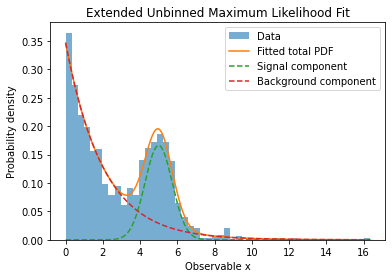

In [18]:


# 1) Simulate unbinned data: mixture of Gaussian "signal" + Exponential "background"
np.random.seed(42)
N_signal_true = 300
N_background_true = 700

# signal: Gaussian with mu=5, sigma=0.8, 300 points
signal_data = np.random.normal(loc=5.0, scale=0.8, size=N_signal_true) 

print(f'Signal is (first five): {signal_data[:5]}')
print(f'Signal is (last five): {signal_data[-5:]}')


# background: exponential decay with scale=2.0 (lambda = 1/2), 700 points
background_data = np.random.exponential(scale=2.0, size=N_background_true)


print(f'Background is (first five): {background_data[:5]}')
print(f'Background is (last five): {background_data[-5:]}')



data = np.hstack([signal_data, background_data])

print(f'Data (first few elements) is: {data[:10]}')  




# 2) Define extended negative log-likelihood
def neg_log_likelihood(params):
    N_s, mu, sigma, N_b, lam = params
    # enforce positive parameters
    if N_s < 0 or sigma <= 0 or N_b < 0 or lam <= 0:
        return np.inf
    
    # probability density for each component
    # basically “plug in” our model distributions to evaluate the likelihood at each data point
    pdf_sig = norm.pdf(data, loc=mu, scale=sigma) 
    pdf_bkg = expon.pdf(data, scale=1/lam)
    
    # mixture PDF
    pdf_tot = (N_s * pdf_sig + N_b * pdf_bkg) / (N_s + N_b) # considering the total 
    
    
    # extended likelihood: Poisson term for total counts + product term
    # But since total N fixed, we minimize sum of -log(pdf_tot)
    ll = np.sum(np.log(pdf_tot))   
    
    # return negative log-likelihood
    return -ll


# 3) Initial guesses for the parameters   # N_s, mu of gaussian, std dev, N_b,  lambda of exponential
initial_guess = [250, 4.8, 1.0, 750, 0.5] 



# 4) minimize() is scipy.optimize tweak, changes the values so as to minimize nll, enlarging the likelihood
# using minimization algorithm Limited-memory BFGS B (bounds) 
result = minimize(neg_log_likelihood, initial_guess, method='L-BFGS-B',
                  bounds=[(0, None), (None, None), (1e-3, None), (0, None), (1e-3, None)])


N_s_fit, mu_fit, sigma_fit, N_b_fit, lam_fit = result.x

print("Fit results:")
print(f"  N_signal  = {N_s_fit:.1f}")
print(f"  mu        = {mu_fit:.3f}")
print(f"  sigma     = {sigma_fit:.3f}")
print(f"  N_bkg     = {N_b_fit:.1f}")
print(f"  lambda    = {lam_fit:.3f}")

# 5) Plot data histogram and fitted model
plt.figure()
counts, bins, _ = plt.hist(data, bins=50, density=True, alpha=0.6, label='Data')

# Plot fitted PDFs
x = np.linspace(0, np.max(data), 500)
pdf_signal = N_s_fit * norm.pdf(x, mu_fit, sigma_fit)  
pdf_bkg = N_b_fit * expon.pdf(x, scale=1/lam_fit)   
pdf_total = (pdf_signal + pdf_bkg) / (N_s_fit + N_b_fit)

plt.plot(x, pdf_total, label='Fitted total PDF')
plt.plot(x, pdf_signal / (N_s_fit + N_b_fit), '--', label='Signal component')
plt.plot(x, pdf_bkg / (N_s_fit + N_b_fit), '--', label='Background component')    

plt.xlabel('Observable x')
plt.ylabel('Probability density')
plt.legend()
plt.title('Extended Unbinned Maximum Likelihood Fit')
plt.show()


## Example run

- **Inputs to `minimize`:**  
  1. The objective function (e.g. `lambda x: quad(x)`)  
  2. An initial guess `x0`

- **Internal steps (e.g. L-BFGS-B):**  
  1. Evaluate the function at the starting point.  
  2. Estimate the gradient (via finite differences).  
  3. Propose a new trial point “downhill” in \(x\).  
  4. Repeat until convergence.

- **Inspecting trial points:**  
  - Use the `callback` argument to capture each `x`.  
  - Or add a `print` inside your function to log `x` as it’s tried. ```


In [2]:
# Example with minimize()
# finding minimum value of (x-3)^2 + 5

def quad(x):
    return (x - 3)**2 + 5

x0 = np.array([0.0])
res = minimize(lambda x: quad(x), x0) # minimize the quad() value, starting with x0

print("Minimum location:", res.x)
print("Minimum value:   ", res.fun)


Minimum location: [3.00000003]
Minimum value:    5.000000000000001


In [23]:
res 

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 5.000000000000001
        x: [ 3.000e+00]
      nit: 2
      jac: [ 5.960e-08]
 hess_inv: [[ 5.000e-01]]
     nfev: 6
     njev: 3

In [8]:
tried = []
def cb(xk):
    tried.append(xk.copy())

x0=np.array([2.9999])
def quad(x):
    return (x - 3)**2 + 100
    
res = minimize(quad, x0, callback=cb)
print("Tried these x-values:", tried)

print("Minimum location:", res.x)
print("Minimum value:   ", res.fun)



Tried these x-values: [array([2.9999999])]
Minimum location: [2.9999999]
Minimum value:    100.00000000000001
